# SC spread across RefEdit-Bench runs

Loads cached Modified VIEScore rows (`metrics/modified_viescore.jsonl`) for the runs in `RUN_NAMES`, keeps samples scored in every run, and shows those whose SC spread (max minus min) is greater than `H`. This notebook reads cached metrics only and makes no VIEScore or API calls.

In [1]:
from framework.utils.project import load_project_environment

PROJECT_ROOT = load_project_environment()
BENCHMARK = 'refedit_bench'
PROMPT_MODE = 'mixed'
RUN_NAMES = [
    'run_20261012_092541_755821',
    'run_20261012_101812_541979',
    'run_20261013_041221_043586',
    'run_20261025_124646_118000',
    'run_20261025_132256_963056',

    # add more run_<timestamp> folder names here
]
H = 2.0
MAX_SHOWN = 20

/Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from evaluation.common import read_jsonl
from evaluation.notebook import load_benchmark, resolve_run_directory

if len(RUN_NAMES) < 2:
    raise ValueError('Set at least two runs in RUN_NAMES.')

context = load_benchmark(BENCHMARK, prompt_mode=PROMPT_MODE)
records_by_id = {record['sample_id']: record for record in context.records}
image_loader = context.image_loader

run_rows = {}
for name in RUN_NAMES:
    run_dir = resolve_run_directory(context.output_dir, name)
    metric_path = run_dir / 'metrics' / 'modified_viescore.jsonl'
    if not metric_path.is_file():
        raise FileNotFoundError(f'Missing cached VIEScore: {metric_path}')
    run_rows[name] = {row['sample_id']: row for row in read_jsonl(metric_path)}
    print(f'{name}: {len(run_rows[name])} cached samples')

run_20261012_092541_755821: 200 cached samples
run_20261012_101812_541979: 200 cached samples
run_20261013_041221_043586: 200 cached samples
run_20261025_124646_118000: 200 cached samples
run_20261025_132256_963056: 200 cached samples


In [3]:
all_ids = set().union(*(set(rows) for rows in run_rows.values()))
common_ids = set.intersection(*(set(rows) for rows in run_rows.values()))
print(f'Samples in every run: {len(common_ids)}')
print(f'Skipped (missing from a run): {len(all_ids) - len(common_ids)}')

spread = {}
for sample_id in common_ids:
    scores = [run_rows[name][sample_id]['sc'] for name in RUN_NAMES]
    spread[sample_id] = max(scores) - min(scores)

selected = sorted(
    (sample_id for sample_id in common_ids if spread[sample_id] > H),
    key=lambda sample_id: spread[sample_id],
    reverse=True,
)
print(f'Samples with SC spread > {H}: {len(selected)}')
print(f'Showing {min(len(selected), MAX_SHOWN)} (MAX_SHOWN={MAX_SHOWN})')

Samples in every run: 200
Skipped (missing from a run): 0
Samples with SC spread > 2.0: 95
Showing 20 (MAX_SHOWN=20)


In [4]:
print('\t'.join(['sample_id', *RUN_NAMES, 'spread']))
for sample_id in selected:
    scores = [f"{run_rows[name][sample_id]['sc']:.2f}" for name in RUN_NAMES]
    print('\t'.join([sample_id, *scores, f'{spread[sample_id]:.2f}']))

sample_id	run_20261012_092541_755821	run_20261012_101812_541979	run_20261013_041221_043586	run_20261025_124646_118000	run_20261025_132256_963056	spread
hard:125	10.00	10.00	0.00	8.00	7.00	10.00
hard:138	0.00	0.00	2.00	9.00	10.00	10.00
hard:122	9.00	10.00	0.00	1.00	0.00	10.00
hard:160	9.00	10.00	0.00	9.00	8.00	10.00
easy:084	9.00	10.00	3.00	10.00	0.00	10.00
easy:038	3.00	9.00	0.00	10.00	9.00	10.00
easy:096	9.00	10.00	9.00	0.00	0.00	10.00
easy:091	10.00	10.00	9.00	0.00	0.00	10.00
hard:127	10.00	2.00	6.00	0.00	0.00	10.00
hard:131	10.00	10.00	9.00	0.00	10.00	10.00
easy:027	10.00	9.00	9.00	0.00	0.00	10.00
easy:043	9.00	10.00	10.00	9.00	0.00	10.00
easy:068	10.00	8.00	10.00	0.00	0.00	10.00
hard:155	10.00	0.00	10.00	10.00	10.00	10.00
easy:086	0.00	10.00	0.00	10.00	10.00	10.00
easy:019	0.00	9.00	0.00	10.00	9.00	10.00
hard:167	9.00	9.00	9.00	0.00	10.00	10.00
hard:179	2.00	10.00	0.00	9.00	10.00	10.00
easy:077	0.00	10.00	0.00	10.00	9.00	10.00
hard:145	0.00	9.00	0.00	10.00	10.00	10.00
hard:101	0.00

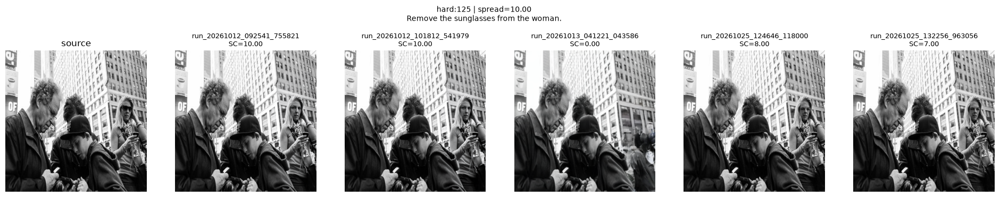

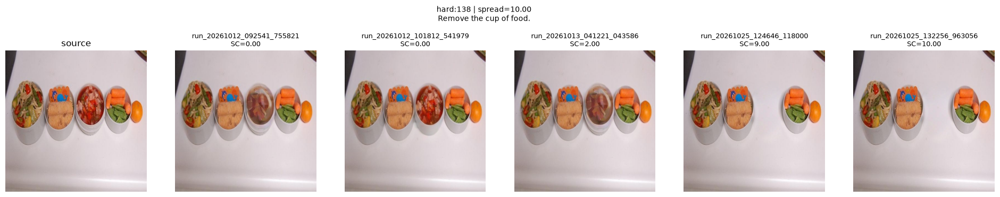

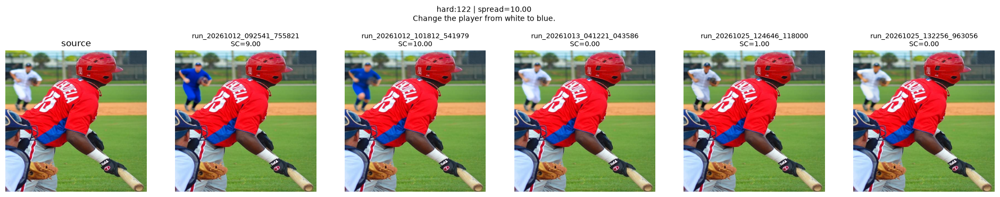

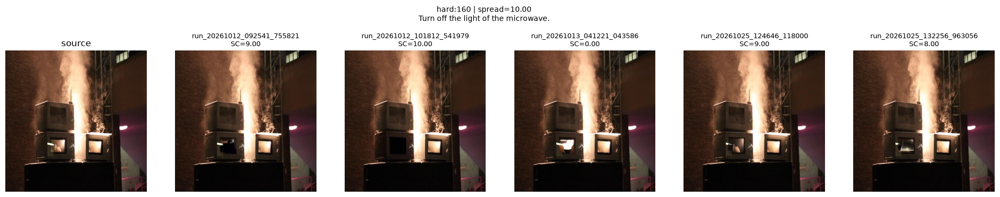

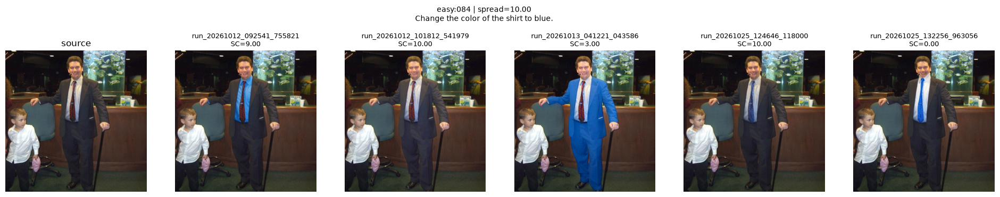

...

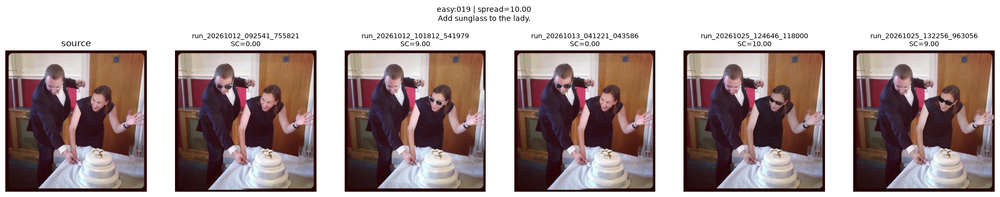

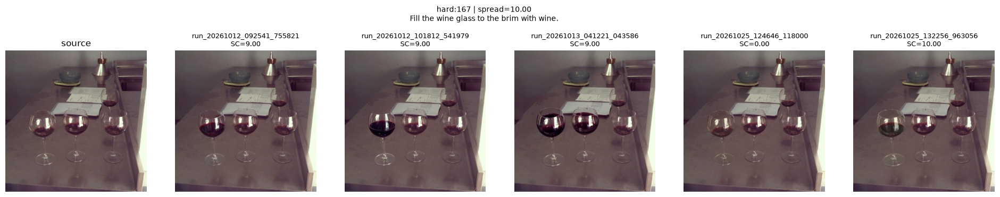

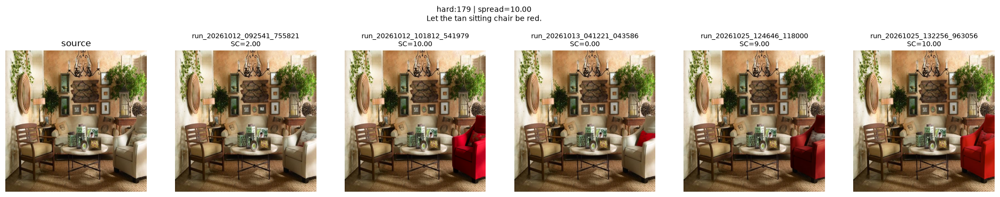

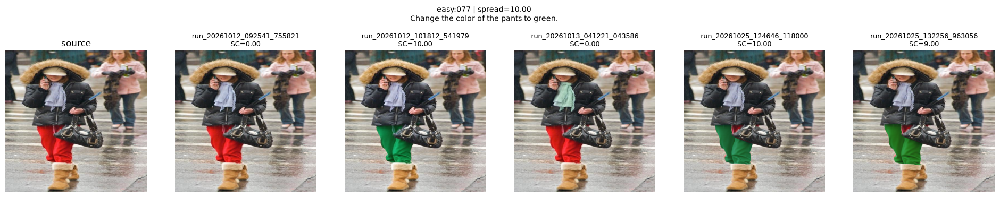

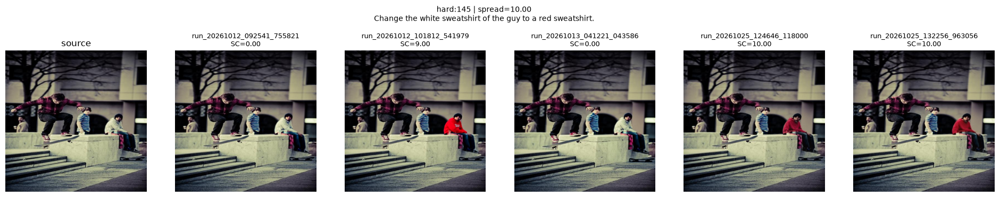

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

for sample_id in selected[:MAX_SHOWN]:
    record = records_by_id[sample_id]
    reference = image_loader.parse_reference(record.get('source_ref'))
    if reference is None:
        raise ValueError(f'Missing source_ref for {sample_id}')
    dataset_id, hf_split, row_index, image_field = reference
    hf_row = image_loader.get_row(dataset_id, hf_split, row_index)
    source = image_loader.as_image(hf_row[image_field])
    instruction = run_rows[RUN_NAMES[0]][sample_id].get('instruction')

    columns = len(RUN_NAMES) + 1
    fig, axes = plt.subplots(1, columns, figsize=(4 * columns, 4.5))
    axes[0].imshow(source)
    axes[0].set_title('source')
    for axis, name in zip(axes[1:], RUN_NAMES):
        row = run_rows[name][sample_id]
        axis.imshow(Image.open(resolve_run_directory(context.output_dir, name) / 'results' / 'images' / row['output_path'].split('/')[-1]))
        axis.set_title(f"{name}\nSC={row['sc']:.2f}", fontsize=9)
    for axis in axes:
        axis.axis('off')
    fig.suptitle(f"{sample_id} | spread={spread[sample_id]:.2f}\n{instruction}", fontsize=10)
    plt.show()